In [ ]:
#그래프 관련 import
import matplotlib.pyplot as plt    
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'   
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

#프로그램 관련 import
import pandas as pd                                        #csv를 읽고 데이터표 정리        
import numpy as np                                         #하나의 배열로 합치거나 평균 계산
from sklearn import svm,metrics                            #분류,예측
from sklearn.model_selection import train_test_split       #학습용,테스트용 나누는 함수
from sklearn.neighbors import KNeighborsClassifier         #가장 가까운 데이터를 보고 종류를 예측하는 머신러닝 모델,분류(정규화클래스)
from sklearn.preprocessing import StandardScaler           #표준편차 값 변환

[ 머신러닝 확인사항 ]
1. 데이터전처리 - null처리
2. 정규화 작업
3. 학습데이터,테스트데이터 분리
4. 데이터 학습, 예측, 정확도
5. 산점도 그래프

In [82]:
#도미-35 (길이는 len()함수로 알아보기)
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

#빙어-14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [83]:
# 데이터 전처리
# 도미와 빙어의 길이 리스트를 연결하고, 무게 리스트도 연결한다.
total_length = bream_length + smelt_length
total_weight = bream_weight + smelt_weight

#정답표를 만드는 코드 (+): 리스트 이어 붙이기  (*):리스트 반복
#label = [1]*35+[0]*14
label = ['도미']*35 + ['빙어']*14

#데이터 합치기
# 리스트로 만드는 방법도 있다.
# data = [[l,w] for l,w in zip(total_length,total_weight)] 
# 길이와 무게를 열로 나란히 붙여 NumPy 배열로 만든다.
# 한 행은 생선 한 마리이며, 각 행은 [길이, 무게] 형태이다.
data = np.column_stack((total_length,total_weight))

In [ ]:
#정규화 작업
#표준점수 = (특성값- 산술평균) / 표준편차
mean = np.mean(data,axis=0)  #행의 기준으로 산술평가
std = np.std(data,axis=0)    #행의 기준으로 표준편차
train_scaled = (data-mean) / std

In [98]:
# 정규화 작업
ss = StandardScaler()              #정규화 선언
ss.fit(data)                       #정규화 학습
train_scaled = ss.transform(data)  #정규화 변환


In [85]:
# 데이터 전처리- 학습데이터 훈련, 테스트데이터 분리
train_data,test_data,train_label,test_label =\
train_test_split(train_scaled,label)

In [86]:
#데이터 학습,데이터 예측, 정확도
clf= KNeighborsClassifier()
clf.fit(train_data,train_label)
result = clf.predict(test_data)                      
score = clf.score(test_data,test_label)               #테스트데이터를 가지고 어느정도 정답을 맞췄는지 확인
# score = metrics.accuracy_score(result,test_label)   #예측되어서 나온 값과 실제정답과 비교
print('정확도 : ', score)


정확도 :  1.0


In [87]:
input1='25,120'
input1= input1.split(',')
input1                       #['25', '120'] : 문자열
input2= list(map(float,input1))
input2                       #[25.0, 120.0] : 실수형

[25.0, 120.0]

In [88]:
##input 받아서 도미인지, 빙어인지 확인하시오.
##길이,무게
input1 = input('생선의 길이와 무게를 입력하시오. (예: 25,120)')
input1 = input1.split(',')
input1                       #['25', '120'] : 문자열
input2= list(map(float,input1))
input2                       #[25.0, 120.0] : 실수형
new_input= (input2-mean)/std
result2 = clf.predict([new_input])
print("예측생선: ",result2)


예측생선:  ['도미']


In [89]:
distances, indexes = clf.kneighbors([new_input])      #도미로 판단하게 된 데이터가 어떤것인지 알려줌

In [95]:
indexes

array([[19, 33, 32,  6,  5]])

In [91]:
data[0]

array([ 25.4, 242. ])

In [92]:
train_scaled[0]   #data값을 정규화 작업한 값

array([-0.16326134, -0.62350364])

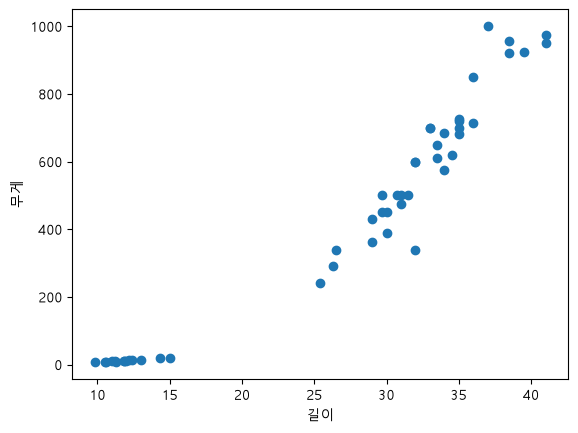

In [93]:
# 그래프 출력
plt.scatter(data[:,0],data[:,1])
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

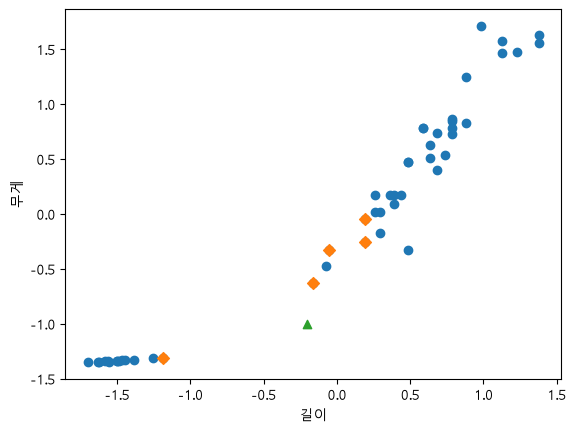

In [94]:
# 정규화 작업 한 그래프 출력
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
plt.scatter(new_input[0],new_input[1],marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()